# Image Enhancement, Generation and Style Transfer

**ESRGAN super-resolution, Stable Diffusion v1.5 and VGG19 neural style transfer**

## Overview

This notebook explores three families of generative and deep-learning models for images:

1. **Image enhancement with a GAN.** A pretrained ESRGAN model (TensorFlow Hub) upscales images 4x. Results are compared with bicubic interpolation both visually and with PSNR/SSIM on a simulated low-resolution benchmark.
2. **Image generation with a diffusion model.** Stable Diffusion v1.5 (Hugging Face `diffusers`) is used for text-to-image and image-to-image generation. The notebook studies the effect of the guidance scale, negative prompts and the img2img strength.
3. **Neural style transfer.** A VGG19 feature extractor and Gram matrices are used to repaint a content image in the style of an artwork by directly optimizing the pixels.

## Technologies

- Python, TensorFlow / Keras, TensorFlow Hub;
- PyTorch and Hugging Face `diffusers`;
- ESRGAN (`captain-pool/esrgan-tf2`), Stable Diffusion v1.5, VGG19 (ImageNet weights);
- Matplotlib, Pandas, Pillow.

## Brief Background

**GANs.** A generative adversarial network (Goodfellow et al., 2014) consists of two networks trained against each other: a generator that produces fake samples and a discriminator that tries to tell them from real data. ESRGAN (Enhanced Super-Resolution GAN) improves SRGAN and restores high-resolution detail from low-resolution images.

**Diffusion models.** Stable Diffusion is a latent diffusion model. During training, Gaussian noise is gradually added to an image; the model learns to predict and remove that noise, conditioned on a text prompt. At inference time an image is produced by denoising random noise step by step.

**Neural style transfer.** The method (Gatys et al., 2015) creates a new image that keeps the content of one image and the style of another. Content is described by deep CNN feature maps, style by the correlations between feature channels (Gram matrices), and the output image is optimized to match both.

> **Hardware and environment.** The notebook was developed on Kaggle with a GPU accelerator and Internet access enabled (models are downloaded from TensorFlow Hub and the Hugging Face Hub). The input image folders are configured in the next section.

## 0. Environment Setup

The first cell installs the libraries that are not always preinstalled. The second one imports everything, fixes the random seeds and defines the input and output paths.

Because TensorFlow (ESRGAN, style transfer) and PyTorch (Stable Diffusion) share one GPU, TensorFlow is told to allocate GPU memory on demand instead of reserving all of it. The Stable Diffusion pipelines are also deleted at the end of Part 2 to free memory for Part 3.

In [20]:
%pip install -q diffusers transformers accelerate tensorflow-hub

Note: you may need to restart the kernel to use updated packages.


In [21]:
import gc
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL.Image
import tensorflow as tf
import tensorflow_hub as hub
import keras
import torch
from IPython import display

# Let TensorFlow allocate GPU memory on demand so that PyTorch can share the GPU
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

# ---- Paths: edit these when running outside Kaggle -------------------------
ESRGAN_INPUT_DIR = Path("/kaggle/input/datasets/bodyastar/esrgan-test-images")
IMG2IMG_INPUT = Path("/kaggle/input/datasets/bodyastar/img2imgprediffusedimages/girl.png")
STYLE_DATA_DIR = Path("/kaggle/input/datasets/soumikrakshit/images-for-style-transfer/Data")
OUTPUT_DIR = Path("/kaggle/working/results")
# ----------------------------------------------------------------------------

for sub in ("esrgan", "stable_diffusion", "style_transfer"):
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)


def to_uint8(array):
    """Convert a float image in the range [0, 255] to a displayable uint8 array."""
    return np.clip(np.rint(np.asarray(array)), 0, 255).astype(np.uint8)


print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))
print("PyTorch CUDA available:", torch.cuda.is_available())

TensorFlow: 2.20.0
PyTorch: 2.11.0+cu128
TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
PyTorch CUDA available: True


## Part 1. Image Enhancement with ESRGAN

### 1.1. Loading the model and preparing images

The pretrained ESRGAN model is loaded from TensorFlow Hub. According to the TensorFlow Hub tutorial, it was trained on the DIV2K dataset using bicubic-downsampled images, so it is designed to restore detail in images degraded in that way.

Each image is processed as follows:

1. decode the file as a 3-channel RGB tensor (this also drops a PNG alpha channel and expands grayscale images);
2. crop it so that its height and width are multiples of 4, as the model expects;
3. convert it to `float32` (values stay in the range 0 to 255) and add a batch dimension.

The output is a 4x larger image. It is clipped to the valid range before display.

In [22]:
ESRGAN_URL = "https://tfhub.dev/captain-pool/esrgan-tf2/1"
esrgan = hub.load(ESRGAN_URL)


def load_for_esrgan(image_path):
    """Read an image as RGB and crop it to a size divisible by 4 (float32, 0-255)."""
    img = tf.image.decode_image(
        tf.io.read_file(str(image_path)), channels=3, expand_animations=False
    )
    height = int(img.shape[0]) // 4 * 4
    width = int(img.shape[1]) // 4 * 4
    img = tf.image.crop_to_bounding_box(img, 0, 0, height, width)
    return tf.cast(img, tf.float32)


def enhance(img):
    """Upscale an (H, W, 3) float32 tensor in [0, 255] by a factor of 4 with ESRGAN."""
    output = esrgan(tf.expand_dims(img, 0))
    return tf.squeeze(tf.clip_by_value(output, 0, 255), axis=0)


def show_pair(left, right, titles, save_path=None):
    fig, axes = plt.subplots(1, 2, figsize=(15, 8))
    for ax, image, title in zip(axes, (left, right), titles):
        ax.imshow(to_uint8(image))
        ax.set_title(title)
        ax.axis("off")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### 1.2. Visual comparison

Every image in the input folder is upscaled and shown next to the original. The figures are also saved to `results/esrgan/`.

> **Note:** Matplotlib rescales both panels to the same display size, so fine detail can look different from the original files. For a careful inspection, open the saved images at full size. If the GPU runs out of memory on very large images, downscale them first.

In [23]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

image_paths = sorted(
    p for p in ESRGAN_INPUT_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)
print(f"Found {len(image_paths)} images in {ESRGAN_INPUT_DIR}")

for path in image_paths:
    original = load_for_esrgan(path)
    enhanced = enhance(original)
    print(f"{path.name}: {original.shape[1]}x{original.shape[0]} -> {enhanced.shape[1]}x{enhanced.shape[0]}")
    show_pair(
        original,
        enhanced,
        ("Original", "ESRGAN x4"),
        save_path=OUTPUT_DIR / "esrgan" / f"comparison_{path.stem}.png",
    )

### 1.3. Quantitative evaluation on a simulated benchmark

A visual comparison is subjective, and for real low-quality photos there is no ground truth. To obtain numbers, the images in the folder are treated as high-resolution references:

1. downscale each reference by a factor of 4 with bicubic interpolation (the degradation ESRGAN was trained for);
2. upscale the result back with (a) plain bicubic interpolation and (b) ESRGAN;
3. compare both reconstructions with the original using **PSNR** (higher is better) and **SSIM** (closer to 1 is better).

PSNR and SSIM reward pixel-level fidelity, whereas ESRGAN is trained to produce sharp, perceptually realistic textures. A model can therefore look better to a human while scoring lower on these metrics, so the numbers should be read together with the visual comparison.

In [24]:
def evaluate_sr(reference):
    """Compare bicubic upscaling and ESRGAN on a simulated 4x downscaled image."""
    height, width = int(reference.shape[0]), int(reference.shape[1])
    low_res = tf.image.resize(reference, (height // 4, width // 4), method="bicubic", antialias=True)
    low_res = tf.clip_by_value(low_res, 0, 255)

    bicubic = tf.clip_by_value(tf.image.resize(low_res, (height, width), method="bicubic"), 0, 255)
    sr = enhance(low_res)

    return {
        "psnr_bicubic": float(tf.image.psnr(reference, bicubic, max_val=255)),
        "psnr_esrgan": float(tf.image.psnr(reference, sr, max_val=255)),
        "ssim_bicubic": float(tf.image.ssim(reference, bicubic, max_val=255)),
        "ssim_esrgan": float(tf.image.ssim(reference, sr, max_val=255)),
    }


rows = []
for path in image_paths:
    reference = load_for_esrgan(path)
    if min(reference.shape[:2]) < 44:  # SSIM needs a minimum image size
        print(f"Skipping {path.name}: image is too small")
        continue
    rows.append({"image": path.name, **evaluate_sr(reference)})

sr_metrics = pd.DataFrame(rows).set_index("image")
sr_metrics.loc["MEAN"] = sr_metrics.mean()
sr_metrics.round(4)

,psnr_bicubic,psnr_esrgan,ssim_bicubic,ssim_esrgan
image,,,,
0801x4.png,22.6197,23.1400,0.5514,0.6194
0802x4.png,27.1498,29.7806,0.8462,0.8557
0803x4.png,26.5398,29.3292,0.8523,0.8868
0804x4.png,21.4771,22.3625,0.5830,0.6583
0805x4.png,24.9408,25.3389,0.6507,0.6990
0806x4.png,25.3269,26.0033,0.7762,0.8028
0807x4.png,22.1161,22.0632,0.5369,0.5614
0808x4.png,24.3525,25.4123,0.7769,0.8018
0809x4.png,25.5021,25.5330,0.5952,0.6352


## Part 2. Image Generation with Stable Diffusion v1.5

### 2.1. Loading the pipeline

Stable Diffusion is run through the `diffusers` library in half precision (`float16`) on the GPU. The original `runwayml/stable-diffusion-v1-5` repository has been removed from the Hugging Face Hub, so a community mirror of the same weights is used. If the mirror is unavailable, replace `SD_MODEL_ID` with another mirror (for example `sd-legacy/stable-diffusion-v1-5`).

The model is released under the CreativeML OpenRAIL-M license, which includes use-based restrictions. The default safety checker stays enabled.

Every generation uses a seeded random generator, so that changing one parameter at a time gives comparable images.

In [25]:
from diffusers import StableDiffusionPipeline, StableDiffusionImg2ImgPipeline
from diffusers.utils import load_image

assert torch.cuda.is_available(), "Stable Diffusion needs a GPU. Enable one in the notebook settings."

SD_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

txt2img = StableDiffusionPipeline.from_pretrained(SD_MODEL_ID, torch_dtype=torch.float16).to("cuda")
txt2img.set_progress_bar_config(disable=True)


def make_generator(seed=SEED):
    return torch.Generator(device="cuda").manual_seed(seed)


def show_grid(images, titles, ncols=3, size=4, save_path=None):
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=10)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

### 2.2. Text-to-image generation

Six prompts in different styles are used. The main generation parameters are:

- `height` / `width`: image size, 512x512 by default for this model and must be a multiple of 8;
- `guidance_scale`: how strictly the model follows the prompt (higher means closer adherence, lower means more freedom);
- `negative_prompt`: concepts the model should steer away from;
- `generator`: a seeded random generator for reproducible results.

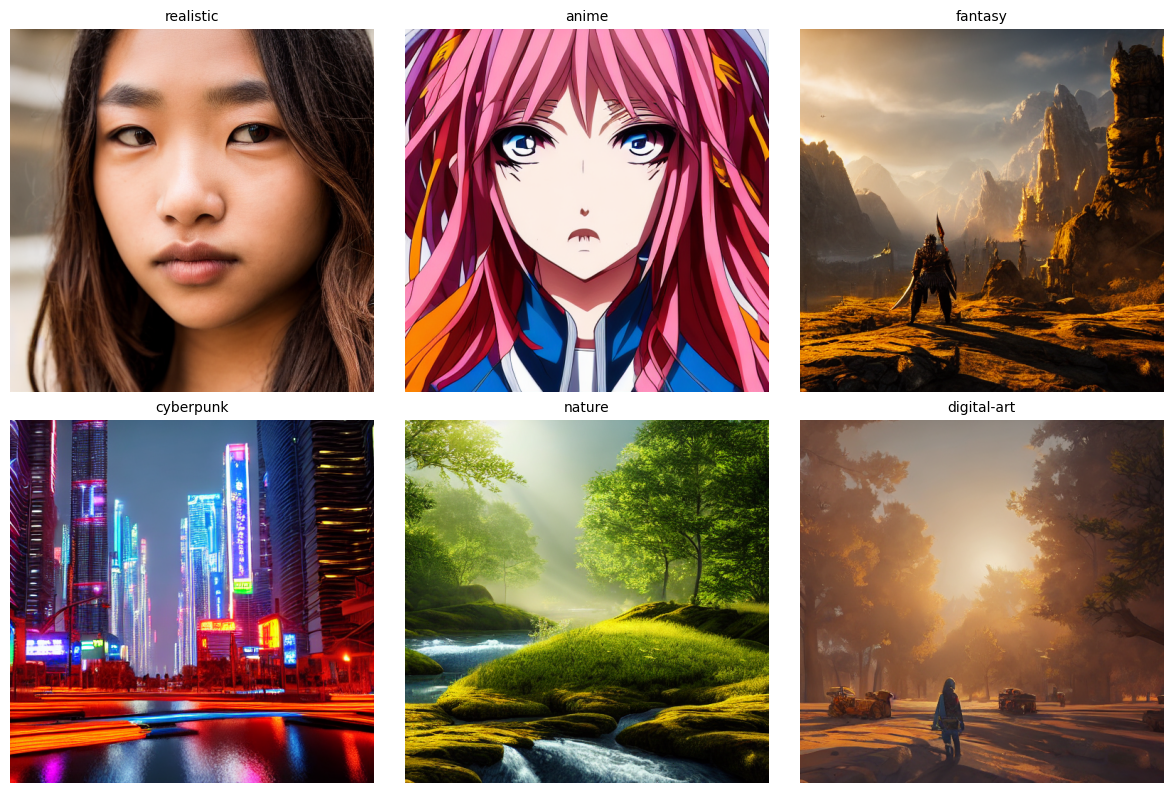

In [26]:
prompts = {
    "realistic": "portrait photo of a young person, natural lighting, detailed skin, shallow depth of field, 50mm lens, ultra realistic, 4k",
    "anime": "anime character, colorful hair, expressive eyes, dynamic pose, vibrant colors, clean lineart, soft shading, high detail",
    "fantasy": "fantasy warrior in armor, glowing sword, epic landscape, mountains, dramatic sky, cinematic lighting, highly detailed",
    "cyberpunk": "cyberpunk city at night, neon lights, futuristic buildings, rain, reflections, cinematic, ultra detailed, 4k",
    "nature": "beautiful landscape, river, green forest, sunlight rays, peaceful atmosphere, ultra realistic, high detail, 4k",
    "digital-art": "digital art illustration, soft lighting, detailed shading, vibrant colors, trending on artstation, masterpiece",
}

negative_prompt = "blurry, low quality, bad anatomy, extra limbs, deformed, watermark, text"

generated = {}
for name, prompt in prompts.items():
    generated[name] = txt2img(
        prompt=prompt,
        negative_prompt=negative_prompt,
        guidance_scale=7,
        height=512,
        width=512,
        generator=make_generator(),
    ).images[0]
    generated[name].save(OUTPUT_DIR / "stable_diffusion" / f"txt2img_{name}.png")

show_grid(
    list(generated.values()),
    list(generated.keys()),
    ncols=3,
    save_path=OUTPUT_DIR / "stable_diffusion" / "txt2img_grid.png",
)

### 2.3. Effect of the guidance scale and the negative prompt

To isolate the effect of a single parameter, the seed and the prompt are kept fixed while one setting changes.

**Guidance scale.** The same landscape prompt is generated with four values. Very low values give the model more freedom and can ignore the prompt, while very high values tend to produce over-saturated, high-contrast images.

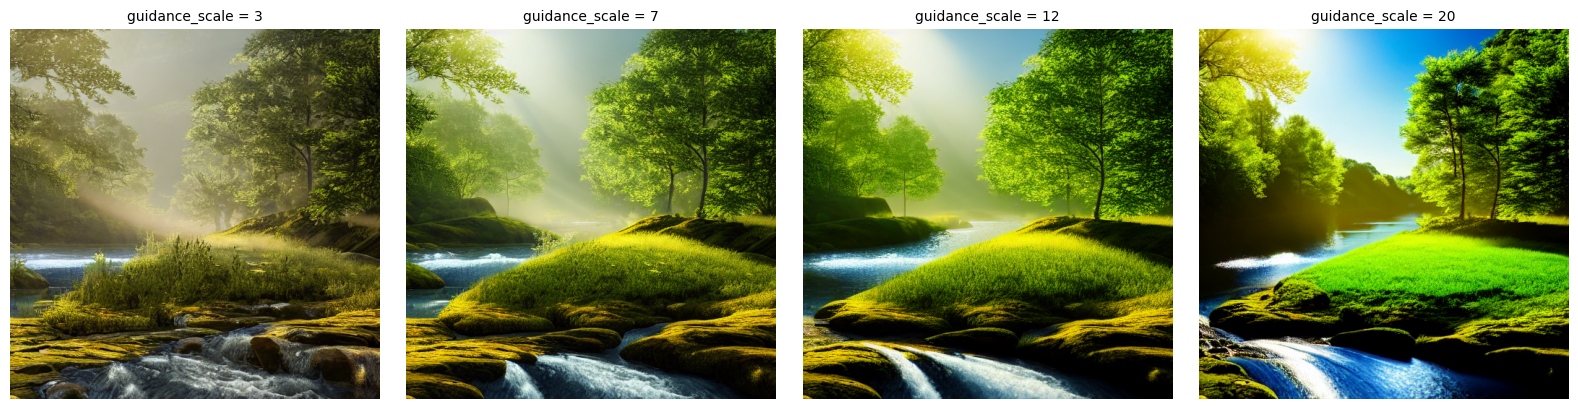

In [27]:
scales = [3, 7, 12, 20]
scale_images = [
    txt2img(
        prompt=prompts["nature"],
        negative_prompt=negative_prompt,
        guidance_scale=scale,
        height=512,
        width=512,
        generator=make_generator(),
    ).images[0]
    for scale in scales
]

show_grid(
    scale_images,
    [f"guidance_scale = {s}" for s in scales],
    ncols=4,
    size=4,
    save_path=OUTPUT_DIR / "stable_diffusion" / "guidance_scale_comparison.png",
)

**Negative prompt.** The portrait prompt is generated with and without the negative prompt, using the same seed.

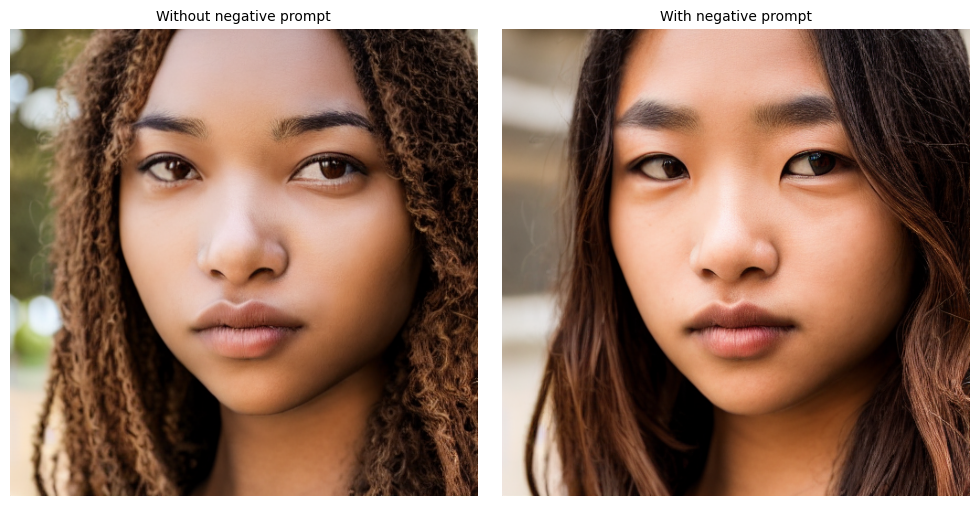

In [28]:
without_negative = txt2img(
    prompt=prompts["realistic"],
    guidance_scale=7,
    height=512,
    width=512,
    generator=make_generator(),
).images[0]

with_negative = generated["realistic"]  # same prompt, seed and guidance scale, with the negative prompt

show_grid(
    [without_negative, with_negative],
    ["Without negative prompt", "With negative prompt"],
    ncols=2,
    size=5,
    save_path=OUTPUT_DIR / "stable_diffusion" / "negative_prompt_comparison.png",
)

### 2.4. Image-to-image generation

In image-to-image generation, the source image is encoded into the latent space and partly noised. The latent diffusion model then receives the text prompt and the noisy latent, predicts the added noise, and removes it step by step to produce a new image.

The key parameter is `strength` (0 to 1): it defines how much noise is added. Low values keep the result close to the source image; high values let the prompt dominate and change the image more. The text-to-image pipeline's components are reused, so the model weights are not loaded twice.

> **Input image:** the example image is read from `IMG2IMG_INPUT` (defined in the setup cell). Use an image you have the right to process; avoid photos of real people unless you have their consent.

In [ ]:
img2img = StableDiffusionImg2ImgPipeline(**txt2img.components)
img2img.set_progress_bar_config(disable=True)


def fit_to_512(image):
    """Resize so that the longer side is 512 px and both sides are multiples of 8."""
    width, height = image.size
    scale = 512 / max(width, height)
    return image.resize(
        (max(8, int(width * scale) // 8 * 8), max(8, int(height * scale) // 8 * 8)),
        PIL.Image.LANCZOS,
    )


init_image = fit_to_512(load_image(str(IMG2IMG_INPUT)).convert("RGB"))

img2img_prompt = (
    "anime girl with blonde hair and playful expression, lying on green grass near a river, "
    "sunny day, nature background, soft breeze, flowers around, relaxed pose, vibrant colors, "
    "detailed, high quality, anime style"
)

strengths = [0.3, 0.5, 0.75, 0.95]
img2img_results = [
    img2img(
        prompt=img2img_prompt,
        negative_prompt=negative_prompt,
        image=init_image,
        strength=strength,
        guidance_scale=7,
        generator=make_generator(),
    ).images[0]
    for strength in strengths
]

show_grid(
    [init_image] + img2img_results,
    ["Source image"] + [f"strength = {s}" for s in strengths],
    ncols=5,
    size=3.5,
    save_path=OUTPUT_DIR / "stable_diffusion" / "img2img_strength_comparison.png",
)

In [30]:
# Free GPU memory before Part 3
del txt2img, img2img
gc.collect()
torch.cuda.empty_cache()

## Part 3. Neural Style Transfer with VGG19

### 3.1. Inputs and helper functions

A content image and a style image (an artwork) are selected. Images are loaded as `float32` tensors in the range [0, 1] and resized so that their longer side is at most 512 px.

In [31]:
style_path = STYLE_DATA_DIR / "Artworks" / "108700.jpg"
content_path = STYLE_DATA_DIR / "TestCases" / "22714.jpg"


def tensor_to_image(tensor):
    """Convert a [0, 1] float tensor (optionally with a batch dimension) to a PIL image."""
    array = np.clip(np.rint(np.array(tensor) * 255), 0, 255).astype(np.uint8)
    if array.ndim > 3:
        assert array.shape[0] == 1
        array = array[0]
    return PIL.Image.fromarray(array)


def load_img(path_to_img, max_dim=512):
    img = tf.io.read_file(str(path_to_img))
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)

    shape = tf.cast(tf.shape(img)[:-1], tf.float32)
    scale = max_dim / tf.reduce_max(shape)
    new_shape = tf.cast(shape * scale, tf.int32)

    img = tf.image.resize(img, new_shape)
    return img[tf.newaxis, :]


def imshow(image, title=None):
    if len(image.shape) > 3:
        image = tf.squeeze(image, axis=0)
    plt.imshow(image)
    plt.axis("off")
    if title:
        plt.title(title)


content_image = load_img(content_path)
style_image = load_img(style_path)

print("Content shape:", content_image.shape)
print("Style shape:", style_image.shape)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
imshow(content_image, "Content image")
plt.subplot(1, 2, 2)
imshow(style_image, "Style image")
plt.show()

### 3.2. Content and style layers

A VGG19 network pretrained on ImageNet is used as a feature extractor. Different depths capture different information:

- **Content** is taken from a single deep layer (`block5_conv2`), which describes *what* is in the image and its overall layout.
- **Style** is taken from the first convolution of each of the five blocks. Early layers describe edges and simple textures, middle layers more complex patterns, and deeper layers object parts and composition.

The classifier head is removed (`include_top=False`) because only the convolutional feature maps are needed, and all network weights are frozen.

In [32]:
CONTENT_LAYERS = ["block5_conv2"]
STYLE_LAYERS = [
    "block1_conv1",
    "block2_conv1",
    "block3_conv1",
    "block4_conv1",
    "block5_conv1",
]

num_content_layers = len(CONTENT_LAYERS)
num_style_layers = len(STYLE_LAYERS)

### 3.3. Gram matrix and the feature extractor

Style is described by the correlations between feature channels, ignoring where in the image they occur. These correlations are captured by the **Gram matrix**:

$$G_{cd} = \frac{1}{H \times W} \sum_{i=1}^{H} \sum_{j=1}^{W} F_{ijc} F_{ijd}$$

The operation `bijc,bijd->bcd` multiplies every channel $c$ by every channel $d$ over all pixel positions (height $i$ and width $j$) and sums the result.

`StyleContentModel` returns the Gram matrices of the style layers and the raw feature maps of the content layer. Inputs are expected in the range [0, 1]; the model converts them to the BGR, mean-subtracted format that VGG19 requires.

In [33]:
def vgg_layers(layer_names):
    """A VGG19 model that returns the feature maps of the requested layers."""
    vgg = keras.applications.VGG19(include_top=False, weights="imagenet")
    vgg.trainable = False
    outputs = [vgg.get_layer(name).output for name in layer_names]
    return keras.Model([vgg.input], outputs)


def gram_matrix(input_tensor):
    result = tf.linalg.einsum("bijc,bijd->bcd", input_tensor, input_tensor)
    input_shape = tf.shape(input_tensor)
    num_locations = tf.cast(input_shape[1] * input_shape[2], tf.float32)
    return result / num_locations


class StyleContentModel(keras.models.Model):
    def __init__(self, style_layers, content_layers):
        super().__init__()
        self.vgg = vgg_layers(style_layers + content_layers)
        self.style_layers = style_layers
        self.content_layers = content_layers
        self.num_style_layers = len(style_layers)
        self.vgg.trainable = False

    def call(self, inputs):
        """Expects a float image in the range [0, 1]."""
        inputs = inputs * 255.0
        preprocessed_input = keras.applications.vgg19.preprocess_input(inputs)
        outputs = self.vgg(preprocessed_input)
        style_outputs = outputs[: self.num_style_layers]
        content_outputs = outputs[self.num_style_layers:]

        style_outputs = [gram_matrix(output) for output in style_outputs]

        return {
            "content": dict(zip(self.content_layers, content_outputs)),
            "style": dict(zip(self.style_layers, style_outputs)),
        }

### 3.4. Targets, loss function and optimizer

The style targets (Gram matrices of the style image) and the content targets (feature maps of the content image) are computed once. The generated image is a trainable variable, initialized with the content image and kept in the range [0, 1].

The loss has three terms:

- **content loss**: mean squared error between the current and target content features;
- **style loss**: mean squared error between the current and target Gram matrices, averaged over the style layers;
- **total variation loss**: penalizes differences between neighboring pixels and suppresses high-frequency noise.

The weights below balance the terms. Increasing `STYLE_WEIGHT` makes the result more stylized, while increasing `CONTENT_WEIGHT` keeps it closer to the content image.

In [34]:
extractor = StyleContentModel(STYLE_LAYERS, CONTENT_LAYERS)

style_targets = extractor(style_image)["style"]
content_targets = extractor(content_image)["content"]

image = tf.Variable(content_image)  # re-run this cell to restart the optimization


def clip_0_1(image):
    return tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0)


opt = keras.optimizers.Adam(learning_rate=0.02, beta_1=0.99, epsilon=1e-1)

STYLE_WEIGHT = 1e-2
CONTENT_WEIGHT = 1e4
TOTAL_VARIATION_WEIGHT = 15


def get_content_loss(base_content, target):
    return tf.reduce_mean(tf.square(base_content - target))


def get_style_loss(gram_style, gram_target):
    return tf.reduce_mean(tf.square(gram_style - gram_target))


def style_content_loss(outputs):
    style_outputs = outputs["style"]
    content_outputs = outputs["content"]

    style_loss = tf.add_n([
        get_style_loss(style_outputs[name], style_targets[name])
        for name in style_outputs.keys()
    ])
    style_loss *= STYLE_WEIGHT / num_style_layers

    content_loss = tf.add_n([
        get_content_loss(content_outputs[name], content_targets[name])
        for name in content_outputs.keys()
    ])
    content_loss *= CONTENT_WEIGHT / num_content_layers

    return style_loss + content_loss


@tf.function()
def train_step(image):
    with tf.GradientTape() as tape:
        outputs = extractor(image)
        loss = style_content_loss(outputs)
        loss += TOTAL_VARIATION_WEIGHT * tf.reduce_sum(tf.image.total_variation(image))

    grad = tape.gradient(loss, image)
    opt.apply_gradients([(grad, image)])
    image.assign(clip_0_1(image))
    return loss

### 3.5. Optimization

The image is optimized with Adam for 10 epochs of 50 steps (500 steps in total). After every epoch the current image is displayed and the loss is recorded. The first step is slower because TensorFlow traces and compiles the `train_step` function.

In [ ]:
EPOCHS = 10
STEPS_PER_EPOCH = 50

loss_history = []
step = 0
start = time.time()

for epoch in range(EPOCHS):
    for _ in range(STEPS_PER_EPOCH):
        step += 1
        loss = train_step(image)
    loss_history.append(float(loss))

    display.clear_output(wait=True)
    display.display(tensor_to_image(image))
    print(f"Train step: {step} | loss: {loss_history[-1]:.2f}")

elapsed = time.time() - start
print(f"Total time: {elapsed:.1f} s")

stylized_path = OUTPUT_DIR / "style_transfer" / "stylized.jpg"
tensor_to_image(image).save(stylized_path)
print("Saved to:", stylized_path)

### 3.6. Result and loss curve

The final figure shows the content image, the style image and the stylized result. The loss curve is recorded once per epoch (every 50 steps).

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (img, title) in zip(
    axes,
    [(content_image, "Content"), (style_image, "Style"), (image, "Stylized result")],
):
    plt.sca(ax)
    imshow(img, title)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "style_transfer" / "style_transfer_result.png", bbox_inches="tight")
plt.show()
plt.close(fig)

plt.figure(figsize=(7, 4))
plt.plot(
    [STEPS_PER_EPOCH * (i + 1) for i in range(len(loss_history))],
    loss_history,
    marker="o",
)
plt.xlabel("Optimization step")
plt.ylabel("Total loss")
plt.title("Style transfer loss")
plt.grid(True)
plt.tight_layout()
plt.show()

## Discussion and Conclusion

This notebook compared three approaches to working with images: GAN-based super-resolution, text-conditioned diffusion models and optimization-based style transfer.

**ESRGAN.** On the simulated 4x benchmark (Section 1.3), ESRGAN outperformed bicubic interpolation on both metrics. The mean PSNR was 25.33 dB against 24.49 dB (+0.84 dB), and the mean SSIM was 0.7359 against 0.6956 (+0.040). SSIM was higher for ESRGAN on all 15 images, and PSNR was higher on 14 of 15; the only exception was image 0807, where bicubic was marginally better (22.12 dB against 22.06 dB). The size of the gain varied a lot: it reached +2.79 dB on image 0803 and +2.63 dB on image 0802, but was close to zero on images 0807, 0809 and 0811. The metrics therefore agree with the visual comparison that ESRGAN recovers more detail than plain interpolation, although the improvement depends on the content of the image. Two caveats apply. First, the test degradation (bicubic downscaling) is exactly the kind the model was trained for, so these results do not show how it would handle real-world degradation such as JPEG artifacts or noise. Second, the file names suggest that the input images are themselves low-resolution (x4) versions, so the references are not true high-resolution images and the absolute values cannot be compared with published DIV2K benchmarks. The comparison between the two methods on the same images remains valid.

**Stable Diffusion.** Output quality depends on the prompt and on the generation parameters, not only on the model. The fixed-seed comparisons isolate the effect of single parameters: the guidance scale (a higher value makes the model follow the prompt more closely at the cost of diversity), the negative prompt (it steers the model away from unwanted features), and the img2img `strength` (a higher value lets the prompt override more of the source image). Typical weaknesses of the model remain visible, for example the duplicated face in the realistic portrait. Stable Diffusion was evaluated qualitatively only.

**Neural style transfer.** The VGG19-based method turns a photo into a stylized image without training any network: only the pixels are optimized. In this run, 500 optimization steps took 37.6 s on a Kaggle GPU, and the final total loss was about 3.73 x 10^6. This value is not meaningful on its own because it combines three weighted terms, so the loss curve serves mainly as a convergence check, not as a measure of quality. The result depends strongly on the layer choice and on the content, style and total variation weights.

**Limitations and further work.** The ESRGAN benchmark uses only 15 images, and the other two parts are evaluated qualitatively. Possible extensions are a larger test set with true high-resolution references and perceptual metrics such as LPIPS, a comparison of ESRGAN with Real-ESRGAN on real-world degradation, a fast feed-forward style transfer model instead of per-image optimization, and a systematic study of the style and content weights.

## References

- Goodfellow, I. et al. *Generative Adversarial Networks.* arXiv:1406.2661, 2014.
- Wang, X. et al. *ESRGAN: Enhanced Super-Resolution Generative Adversarial Networks.* arXiv:1809.00219, 2018.
- Rombach, R. et al. *High-Resolution Image Synthesis with Latent Diffusion Models.* arXiv:2112.10752, 2021.
- Gatys, L. A., Ecker, A. S., Bethge, M. *A Neural Algorithm of Artistic Style.* arXiv:1508.06576, 2015.
- Simonyan, K., Zisserman, A. *Very Deep Convolutional Networks for Large-Scale Image Recognition.* arXiv:1409.1556, 2014.
- Agustsson, E., Timofte, R. *NTIRE 2017 Challenge on Single Image Super-Resolution: Dataset and Study.* CVPR Workshops, 2017.
- Timofte, R. et al. *NTIRE 2017 Challenge on Single Image Super-Resolution: Methods and Results.* CVPR Workshops, 2017.
- TensorFlow Hub tutorial: *Image Super Resolution using ESRGAN*; TensorFlow tutorial: *Neural style transfer*.